## Running some double KO stuff to see how the models perform on double knockouts that they haven't seen before


In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Models.NeuralODE import PhoenixOnlyAddLayers, PhoenixAddAndProdLayers
from halcyon.Models.CellBox import CellBox

# import torch.multiprocessing as mp
import multiprocessing as mp

from halcyon.Trainer import TrainingJob, run_training_job

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging

import torch
import numpy as np
import random

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 


logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

## Data generation

In [2]:
# nr_genes_list = [32, 64, 128]
nr_genes_list = [10]
# nr_modules_list = [16, 5, 10]
nr_modules_list = [2]
sparsity_list = [0.05]

sim_outputs = []
for nr_genes in nr_genes_list: 
    for nr_modules in nr_modules_list: 
        for sparsity in sparsity_list: 
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = Path("../data/double_ko_data") / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_result = gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
            )
            sim_outputs.append(sim_result) 
sim_outputs

2025-10-29 16:55:01,455 - INFO - Generating network
Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: (Node_0) + ~(Node_2)
my_network: Node_1: (Node_3*Node_4) + (Node_1)
my_network: Node_2: (Node_2) + (Node_0)
my_network: Node_3: ~(Node_1) + (Node_3)
my_network: Node_4: (Node_3) + ~(Node_1)
my_network: Node_5: (Node_1) + ~(Node_5) + (Node_3) + ~(Node_4)
my_network: Node_6: ~(Node_1) + (Node_3)
my_network: Node_7: (Node_0)
my_network: Node_8: (Node_7~Node_0)
my_network: Node_9: (Node_1)
Writing file /lustre/BIF/nobackup/noord087/phd/HALCYON/notebooks/../data/double_ko_data/genes_10_modules_2_sparsity_0.05/my_network.xml

Thomas Schaffter (thomas.schaff...@gmail.com)
Daniel Marbach (daniel.marb...@gmail.com)
Gilles Roulet (gilles.rou...@gmail.com)

http://tschaffter.ch/projects/gnw
2025-10-29 16:55:02,181 - INFO - S

[SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/double_ko_data/genes_10_modules_2_sparsity_0.05'), network_name='my_network', nr_genes=10, nr_modules=2, sparsity=0.05, keep_self_interactions=True)]

## Model fitting

In [3]:
# only fitting to one simulation
sim_result = sim_outputs[0]

In [4]:
devices = ["cuda:0", "cuda:1"]
train_jobs: list[TrainingJob] = []
train_steps = 100

# hidden_sizes = [10, 20, 30]

# for i, hidden_size in enumerate(hidden_sizes):
#     train_jobs.extend([
#         TrainingJob(PhoenixAddAndProdLayers, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[i % len(devices)], 'hidden_size': hidden_size}, optimizer_kwargs={'lr': .1})

#     ])
#     train_jobs.extend([
#     TrainingJob(PhoenixOnlyAddLayers, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[i % len(devices)], 'hidden_size': hidden_size}, optimizer_kwargs={'lr': .1})
# ])


train_jobs.extend([
    TrainingJob(PhoenixAddAndProdLayers, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[1], 'hidden_size': 2}, optimizer_kwargs={'lr': .1})
    
])
train_jobs.extend([
TrainingJob(PhoenixOnlyAddLayers, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[0], 'hidden_size': 2}, optimizer_kwargs={'lr': .1})
    
])


train_jobs.extend([
    TrainingJob(CellBox, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[1], 'self_activations': True}, optimizer_kwargs={'lr': .1})
    
])


len(train_jobs)


3

In [ ]:
mp.set_start_method("spawn", force=True)  
with mp.Pool(processes=4) as pool:
    pool.map(run_training_job, train_jobs)

In [5]:
from halcyon.FittedTrainingJobList import FittedTrainingJobList


result_list = FittedTrainingJobList.from_train_jobs(train_jobs)

2025-10-29 16:55:07,984 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/double_ko_data/genes_10_modules_2_sparsity_0.05/trained_trainer_PhoenixAddAndProdLayers_hidden_size_2_lr_0.1.pt
2025-10-29 16:55:08,054 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/double_ko_data/genes_10_modules_2_sparsity_0.05/trained_trainer_PhoenixOnlyAddLayers_hidden_size_2_lr_0.1.pt
2025-10-29 16:55:08,106 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/double_ko_data/genes_10_modules_2_sparsity_0.05/trained_trainer_CellBox_self_activations_True_lr_0.1.pt


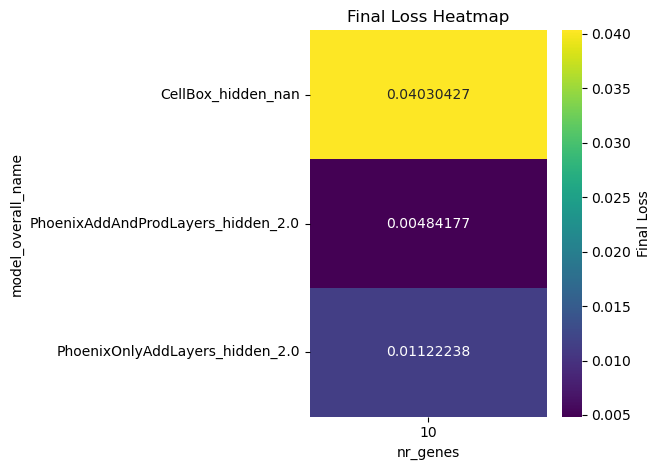

In [6]:
result_list.final_loss_heatmap()

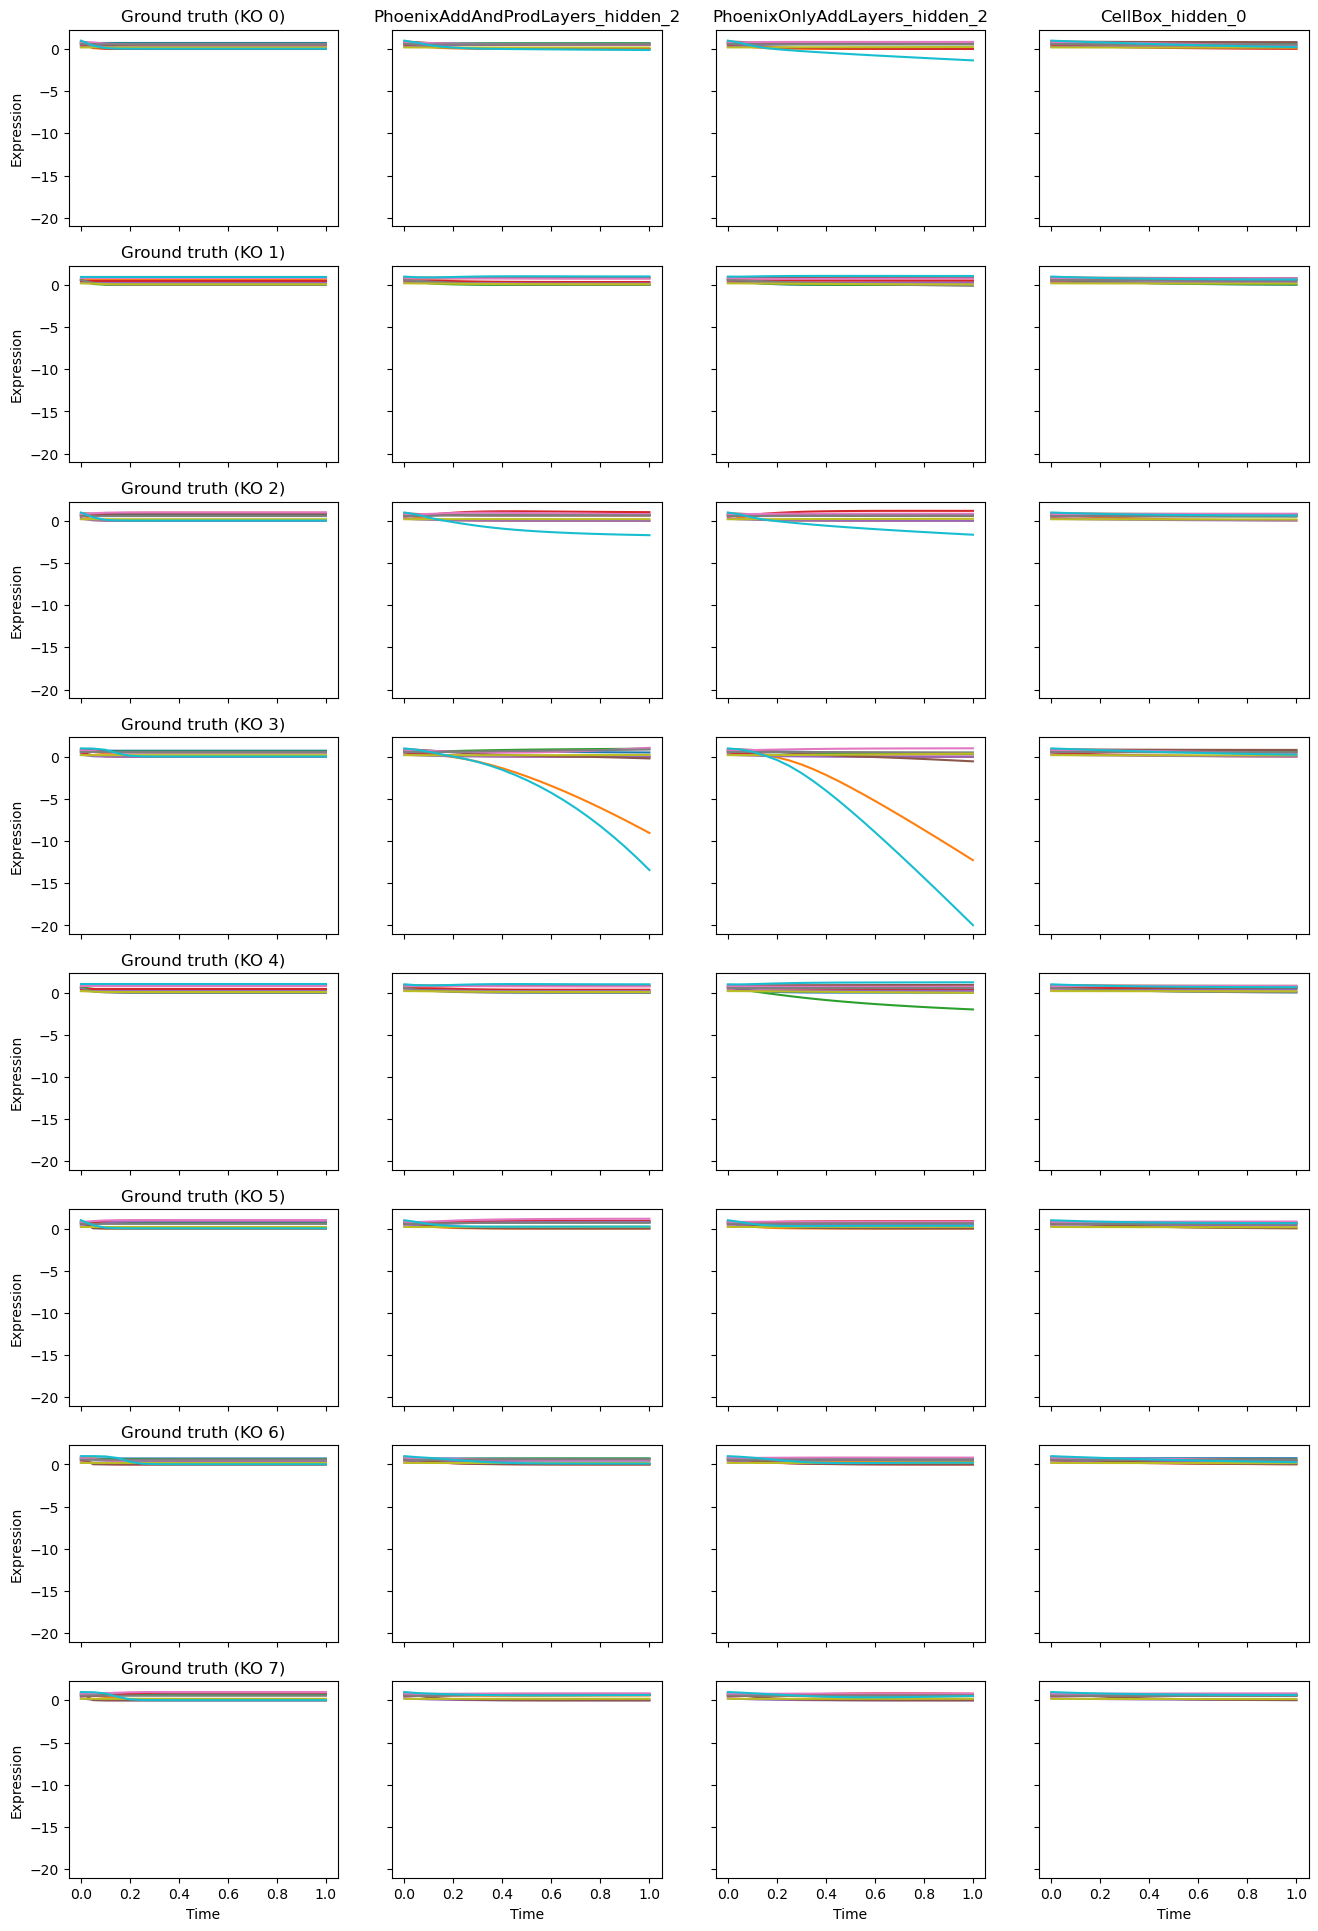

In [7]:
result_list.plot_all_model_fits_into_one_fig(only_double_ko=True)

In [ ]:
# Assuming `results` is a list of dicts
df = result_list.summary_dataframe()
df

In [ ]:
result_list[1].trainer.plot_fit_vs_real(top_n=3, show_legend=False)

In [ ]:
result_list[5].trainer.plot_fit_vs_real(top_n=3, show_legend=False)